# Etapa 2 - Modelagem e Avaliacao

Comparacao de tres familias de modelos do Scikit-Learn (linear, arvores e rede neural) com validacao cruzada estratificada, escolha do campeao e analise do resultado. A logica de treino fica em `src/churn/train.py`, e este notebook documenta os experimentos e as leituras.

In [1]:
import sys
sys.path.append("../src")

import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

from churn.config import SEED, FIGURES_DIR, RESULTS_DIR, MODEL_PATH, METADATA_PATH
from churn.data import load_raw_data, clean_data, make_train_test
from churn.train import compare_models
from churn.evaluate import compute_metrics

warnings.filterwarnings("ignore")
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Dados e divisao

In [2]:
df = clean_data(load_raw_data())
X_train, X_test, y_train, y_test = make_train_test(df)
print(X_train.shape, X_test.shape, round(y_train.mean(), 4), round(y_test.mean(), 4))

(5634, 19) (1409, 19) 0.2654 0.2654


## 2. Treino e validacao cruzada

Os tres modelos usam o mesmo pre-processamento dentro de um `Pipeline`, entao imputacao, escala e one-hot sao ajustados apenas nos folds de treino. A validacao e estratificada com 5 folds e seed fixa. O limiar de decisao de cada modelo vem das previsoes out-of-fold do treino, o que mantém o teste intocado.

In [3]:
table, artefacts = compare_models(X_train, y_train, X_test, y_test)
models = artefacts["models"]
thresholds = artefacts["thresholds"]

logistic_regression    cv_auc=0.8460 test_auc=0.8414


random_forest          cv_auc=0.8471 test_auc=0.8425


mlp                    cv_auc=0.8423 test_auc=0.8369


## 3. Tabela comparativa

In [4]:
cols = ["model", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_f1_mean", "cv_recall_mean", "cv_precision_mean",
        "threshold", "test_roc_auc", "test_f1", "test_recall", "test_precision", "test_business_value"]
table[cols].reset_index(drop=True)

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_recall_mean,cv_precision_mean,threshold,test_roc_auc,test_f1,test_recall,test_precision,test_business_value
0,random_forest,0.8471,0.0094,0.6314,0.7425,0.5495,0.4490,0.8425,0.6303,0.8021,0.5190,19320.0
1,logistic_regression,0.8460,0.0124,0.6286,0.8013,0.5174,0.5741,0.8414,0.6180,0.7246,0.5388,18600.0
2,mlp,0.8423,0.0138,0.5840,0.5271,0.6567,0.3012,0.8369,0.6156,0.6979,0.5506,18540.0


Leitura da tabela.

- Os tres modelos ficam muito proximos em ROC-AUC (cerca de 0,84 a 0,85). A diferenca entre o Random Forest e a Regressao Logistica na validacao cruzada (0,0011) e bem menor que o desvio entre folds (cerca de 0,01), portanto nao e estatisticamente relevante.
- O Random Forest tem a melhor media de AUC na validacao e tambem o melhor F1 e o maior valor de negocio no teste, entao e escolhido como campeao pelo criterio definido (maior ROC-AUC medio na validacao cruzada).
- O MLP, sem ajuste de peso de classe, precisou de um limiar baixo e mostrou recall menor na validacao.
- Em um problema tabular pequeno como este, o ganho dos modelos mais complexos sobre o baseline linear e marginal. A Regressao Logistica continua sendo uma alternativa valida quando interpretabilidade pesa mais.

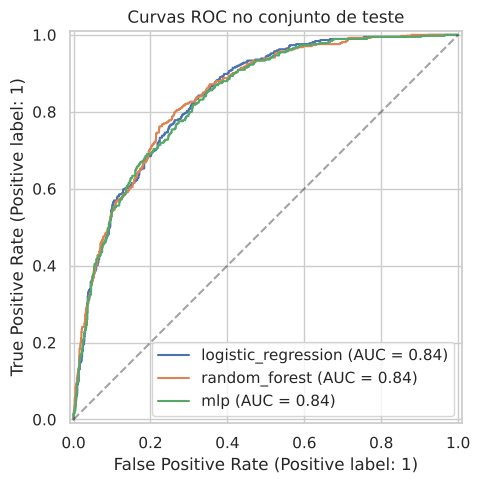

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("Curvas ROC no conjunto de teste")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_curvas_roc.png", dpi=150)
plt.show()

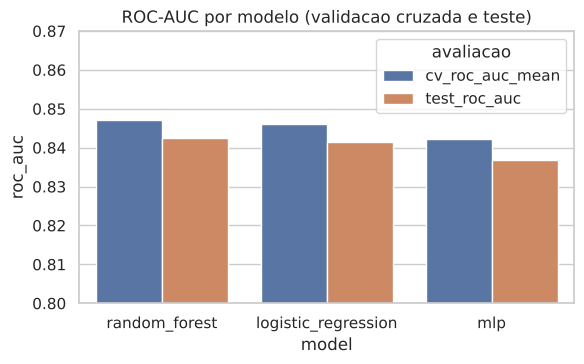

In [6]:
plot = table.melt(id_vars="model", value_vars=["cv_roc_auc_mean", "test_roc_auc"],
                  var_name="avaliacao", value_name="roc_auc")
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.barplot(data=plot, x="model", y="roc_auc", hue="avaliacao", ax=ax)
ax.set_ylim(0.8, 0.87)
ax.set_title("ROC-AUC por modelo (validacao cruzada e teste)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_comparacao_modelos.png", dpi=150)
plt.show()

## 4. Modelo campeao

Campeao: random_forest | limiar: 0.449
{'roc_auc': 0.8425, 'f1': 0.6303, 'precision': 0.519, 'recall': 0.8021, 'business_value': 19320.0, 'threshold': 0.449}


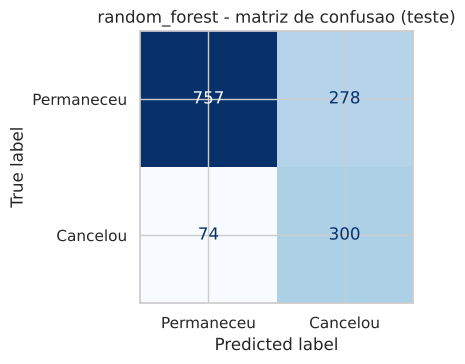

In [7]:
champion = table.iloc[0]["model"]
pipe = models[champion]
thr = thresholds[champion]
proba = pipe.predict_proba(X_test)[:, 1]
print("Campeao:", champion, "| limiar:", round(thr, 4))
print({k: round(v, 4) for k, v in compute_metrics(y_test, proba, thr).items()})

fig, ax = plt.subplots(figsize=(4.5, 3.8))
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= thr).astype(int), ax=ax, cmap="Blues", colorbar=False,
                                        display_labels=["Permaneceu", "Cancelou"])
ax.set_title(f"{champion} - matriz de confusao (teste)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_campeao_confusao.png", dpi=150)
plt.show()

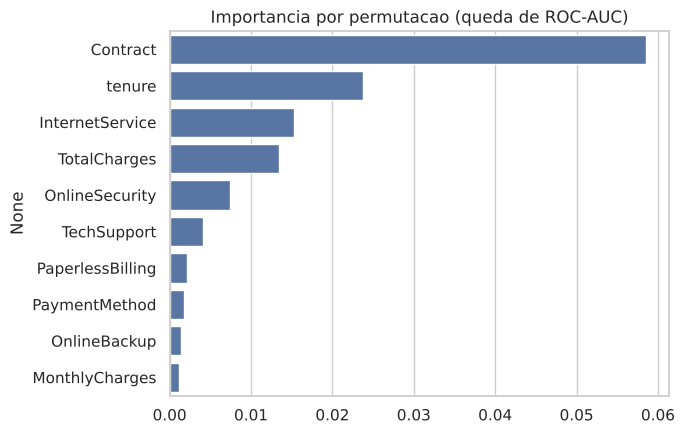

Contract            0.0585
tenure              0.0237
InternetService     0.0153
TotalCharges        0.0134
OnlineSecurity      0.0074
TechSupport         0.0040
PaperlessBilling    0.0021
PaymentMethod       0.0017
OnlineBackup        0.0014
MonthlyCharges      0.0012
dtype: float64

In [8]:
# Importancia por permutacao nas colunas originais (mede queda de AUC ao embaralhar cada feature)
imp = permutation_importance(pipe, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp_df = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = imp_df.head(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top.values, y=top.index, ax=ax, color="#4C72B0")
ax.set_title("Importancia por permutacao (queda de ROC-AUC)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_importancia_features.png", dpi=150)
plt.show()
top.round(4)

As variaveis mais relevantes sao as que a EDA ja apontava, com destaque para tipo de contrato, tenure, tipo de internet e cobrancas totais. Isso da confianca de que o modelo aprendeu sinais de negocio coerentes, e nao ruido.

## 5. Registro dos experimentos

In [9]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
table.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
imp_df.round(5).to_csv(RESULTS_DIR / "feature_importance.csv", header=["permutation_importance_auc_drop"])
print(open(METADATA_PATH, encoding="utf-8").read()[:600])

{
  "champion": "random_forest",
  "selection_criterion": "maior ROC-AUC medio na validacao cruzada (5 folds)",
  "threshold": 0.4489634562115785,
  "features": [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
  ],
  "seed": 42,
  "sklearn_version": "1.9.1",
  "trained_on


## 6. Conclusoes da Etapa 2

- Random Forest, Regressao Logistica e MLP entregam ROC-AUC proximo de 0,84 a 0,85, com diferencas dentro do ruido da validacao cruzada.
- O Random Forest e o campeao pelo criterio definido e fica salvo em `models/churn_model.joblib`, com limiar e metadados em `models/model_metadata.json`.
- O baseline linear continua competitivo, o que e um resultado esperado para dados tabulares com poucas features.
- Proximos passos possiveis, fora do escopo deste trabalho, incluem busca de hiperparametros, calibracao das probabilidades e custos reais de retencao.